In [2]:
import pandas as pd
import json

PATH_RAW = '../data/raw/'

account= pd.read_csv(f'{PATH_RAW}ravenstack_accounts.csv')
churn_events= pd.read_csv(f'{PATH_RAW}ravenstack_churn_events.csv')
feature_usage= pd.read_csv(f'{PATH_RAW}ravenstack_feature_usage.csv')
subscriptions= pd.read_csv(f'{PATH_RAW}ravenstack_subscriptions.csv')
support_tickets= pd.read_csv(f'{PATH_RAW}ravenstack_support_tickets.csv')


In [3]:
#date sütunlarını str den DATE type a dönüştürelim

account['signup_date'] = pd.to_datetime(account['signup_date'], errors='coerce')
churn_events['churn_date'] = pd.to_datetime(churn_events['churn_date'], errors='coerce')
feature_usage['usage_date'] = pd.to_datetime(feature_usage['usage_date'], errors='coerce')
subscriptions['start_date'] = pd.to_datetime(subscriptions['start_date'], errors='coerce')
subscriptions['end_date'] = pd.to_datetime(subscriptions['end_date'], errors='coerce')
support_tickets['submitted_at'] = pd.to_datetime(support_tickets['submitted_at'], errors='coerce')
support_tickets['closed_at'] = pd.to_datetime(support_tickets['closed_at'], errors='coerce')

In [4]:
#3 aylık bir tahminleme modeli kuracağız

HORIZON_DAYS = 90

snapshot_dates = pd.date_range(start='2023-07-01', end='2024-10-01', freq='MS')

print(len(snapshot_dates))
print(snapshot_dates)

16
DatetimeIndex(['2023-07-01', '2023-08-01', '2023-09-01', '2023-10-01',
               '2023-11-01', '2023-12-01', '2024-01-01', '2024-02-01',
               '2024-03-01', '2024-04-01', '2024-05-01', '2024-06-01',
               '2024-07-01', '2024-08-01', '2024-09-01', '2024-10-01'],
              dtype='datetime64[ns]', freq='MS')


In [5]:
snapshots = pd.DataFrame({'snapshot_date': snapshot_dates})

base = pd.merge(
    account[['account_id', 'signup_date']],
    snapshots,
    how='cross'
)

print(len(base))
base.head()

8000


,account_id,signup_date,snapshot_date
0,A-2e4581,2024-10-16,2023-07-01
1,A-2e4581,2024-10-16,2023-08-01
2,A-2e4581,2024-10-16,2023-09-01
3,A-2e4581,2024-10-16,2023-10-01
4,A-2e4581,2024-10-16,2023-11-01


In [6]:
#Henüz kaydolmamış hesapları çıkaralım
base = base[base['signup_date'] < base['snapshot_date']].reset_index(drop=True)

print(len(base))

4100


In [7]:
# 4a. Her snapshot satırını, o hesabın tüm churn tarihleriyle eşleştirelim
pairs = pd.merge(
    base[['account_id', 'snapshot_date']],
    churn_events[['account_id', 'churn_date']],
    on='account_id',
    how='inner'
)

# 4b. Churn bu satırın penceresine düşüyor mu?
window_end = pairs['snapshot_date'] + pd.Timedelta(days=HORIZON_DAYS)
pairs['in_window'] = (pairs['churn_date'] >= pairs['snapshot_date']) & (pairs['churn_date'] < window_end)

# 4c. Hesap + snapshot düzeyine geri topla: penceresinde en az bir churn var mı?
labels = (
    pairs.groupby(['account_id', 'snapshot_date'], as_index=False)['in_window']
    .max()
    .rename(columns={'in_window': 'churn_90d'})
)

# 4d. Etiketleri base tablosuna ekleyelim
target = pd.merge(
    base,
    labels,
    on=['account_id', 'snapshot_date'],
    how='left',
    validate='one_to_one'
)
target['churn_90d'] = target['churn_90d'].eq(True).astype(int)

target.head()

,account_id,signup_date,snapshot_date,churn_90d
0,A-43a9e3,2023-08-17,2023-09-01,0
1,A-43a9e3,2023-08-17,2023-10-01,0
2,A-43a9e3,2023-08-17,2023-11-01,0
3,A-43a9e3,2023-08-17,2023-12-01,0
4,A-43a9e3,2023-08-17,2024-01-01,0


rows: 4100
duplicate account+snapshot: 0
overall positive rate: 22.5%
               count   mean
snapshot_date              
2023-07-01       109  0.128
2023-08-01       123  0.138
2023-09-01       139  0.144
2023-10-01       162  0.167
2023-11-01       182  0.181
2023-12-01       207  0.169
2024-01-01       227  0.185
2024-02-01       243  0.189
2024-03-01       256  0.199
2024-04-01       283  0.216
2024-05-01       305  0.226
2024-06-01       327  0.266
2024-07-01       348  0.247
2024-08-01       374  0.270
2024-09-01       395  0.276
2024-10-01       420  0.295


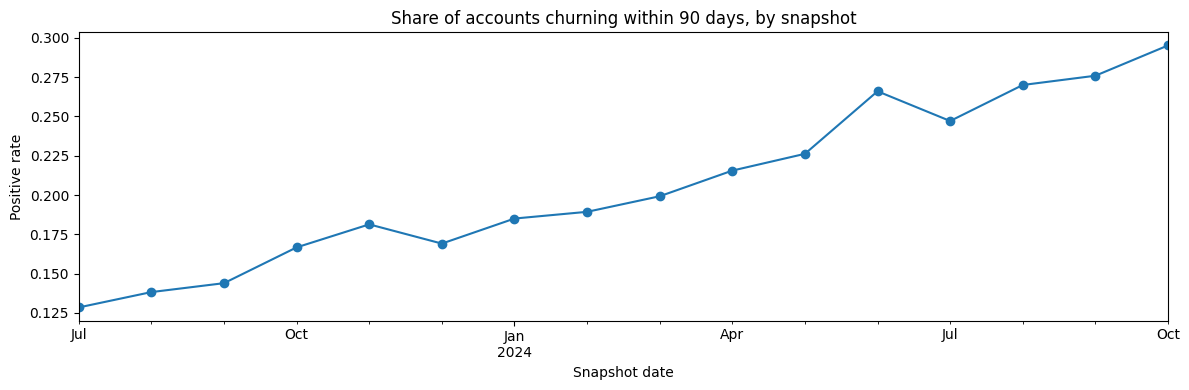

In [8]:
#Doğrulama
# Satır sayısı ve grain
import matplotlib.pyplot as plt
print("rows:", len(target))
print("duplicate account+snapshot:", target.duplicated(subset=['account_id', 'snapshot_date']).sum())

# Genel pozitif oranı
print(f"overall positive rate: {target['churn_90d'].mean():.1%}")

# Snapshot başına hesap sayısı ve pozitif oranı
per_snapshot = target.groupby('snapshot_date')['churn_90d'].agg(['count', 'mean'])
print(per_snapshot.round(3))

ax = per_snapshot['mean'].plot(marker='o', figsize=(12, 4), title='Share of accounts churning within 90 days, by snapshot')
ax.set_xlabel('Snapshot date')
ax.set_ylabel('Positive rate')
plt.tight_layout()
plt.show()

In [9]:
# En çok churn eden hesaplardan birini seç
example_id = churn_events['account_id'].value_counts().index[0]

print("Churn dates:")
print(churn_events.loc[churn_events['account_id'] == example_id, 'churn_date'].sort_values().to_list())

target[target['account_id'] == example_id]

Churn dates:
[Timestamp('2023-12-04 00:00:00'), Timestamp('2024-03-09 00:00:00'), Timestamp('2024-05-04 00:00:00'), Timestamp('2024-05-08 00:00:00'), Timestamp('2024-09-12 00:00:00')]


,account_id,signup_date,snapshot_date,churn_90d
1079,A-180abf,2023-08-14,2023-09-01,0
1080,A-180abf,2023-08-14,2023-10-01,1
1081,A-180abf,2023-08-14,2023-11-01,1
1082,A-180abf,2023-08-14,2023-12-01,1
1083,A-180abf,2023-08-14,2024-01-01,1
1084,A-180abf,2023-08-14,2024-02-01,1
1085,A-180abf,2023-08-14,2024-03-01,1
1086,A-180abf,2023-08-14,2024-04-01,1
1087,A-180abf,2023-08-14,2024-05-01,1
1088,A-180abf,2023-08-14,2024-06-01,0


### Hedef tablosu

Her ayın 1'inde bir snapshot aldım (2023-07-01 ile 2024-10-01 arası, 16 snapshot). Her snapshot'ta, o tarihten önce kaydolmuş hesaplar var. Hedef: snapshot tarihinden itibaren 90 gün içinde (T ≤ churn_date < T+90) en az bir churn event'i varsa 1.

Son snapshot 2024-10-01, çünkü penceresi 30 Aralık'ta kapanıyor ve veri 31 Aralık'ta bitiyor. Daha sonraki snapshot'ların sonucunu göremiyorum.

Kontroller:
- 4.100 satır, hesap + snapshot ikilisi benzersiz
- Genel pozitif oranı %22.5
- Pozitif oranı zamanla artıyor: ilk snapshot'ta %12.8, son snapshot'ta %29.5. Zamana göre split yapınca test setinin churn oranı train'den yüksek olacak
- Bir hesabı (A-180abf) elle kontrol ettim, churn tarihlerine göre bütün etiketler doğru. 90 günlük pencerenin sınırı da doğru çalışıyor

Not: train ile test arasında 90 günlük boşluk bırakmam lazım, yoksa train'in son etiketleri test dönemindeki churn'lere bakıyor olur.

## Feature engineering

Her satır için sadece snapshot tarihinden (T) önceki bilgileri kullanıyorum.

Kullandığım gruplar:
- **Hesap:** sektör, ülke, kazanım kanalı (kayıt anında belli olan bilgiler) ve hesap yaşı
- **Abonelik:** T'den önce başlamış abonelikler, T'de aktif olanların MRR'ı ve koltuk sayısı, en son aboneliğin planı ve fatura döngüsü, upgrade/downgrade sayıları
- **Kullanım:** son 30 ve 90 gündeki kullanım, hata, aktif gün, farklı özellik sayısı, trend ve son kullanımdan bu yana geçen gün. Kayıttan önceki kullanım satırları çıkarıldı
- **Destek:** son 90 gündeki ve toplam ticket sayısı, T'de açık ticket'lar. Çözüm süresi, memnuniyet ve eskalasyon sadece T'den önce kapanmış ticket'lardan, çünkü açık bir ticket'ın bu bilgileri T'de henüz belli değil. Kayıttan önceki ticket'lar çıkarıldı
- **Geçmiş churn:** T'den önceki churn sayısı ve son churn'den bu yana geçen gün

Kullanmadıklarım:
- churn_flag (accounts ve subscriptions): hedefi doğrudan veriyor
- accounts'taki plan_tier, seats, is_trial: hesabın bugünkü durumunu mu yoksa kayıt anını mı gösteriyor bilmiyorum, aynı bilgiyi subscriptions'tan T'ye göre alıyorum
- auto_renew_flag: ne zaman değiştiği belli değil, churn'e yakın kapatılmış olabilir
- churn_events'teki reason_code, refund, feedback, preceding_* bayrakları: churn anında veya sonrasında kaydediliyor
- arr_amount: MRR'ın 12 katı, ek bilgi taşımıyor

Varsayım: upgrade_flag ve downgrade_flag'in abonelik başladığında belli olduğunu kabul ediyorum.

In [10]:
keys = ['account_id', 'snapshot_date']
snap = target[keys].copy()

In [11]:
#Hesap Özellikleri
acc_static = account[['account_id', 'industry', 'country', 'referral_source']]

features = pd.merge(target, acc_static, on='account_id', how='left', validate='many_to_one')
features['tenure_days'] = (features['snapshot_date'] - features['signup_date']).dt.days

print(len(features))
features.head()

4100


,account_id,signup_date,snapshot_date,churn_90d,industry,country,referral_source,tenure_days
0,A-43a9e3,2023-08-17,2023-09-01,0,FinTech,IN,other,15
1,A-43a9e3,2023-08-17,2023-10-01,0,FinTech,IN,other,45
2,A-43a9e3,2023-08-17,2023-11-01,0,FinTech,IN,other,76
3,A-43a9e3,2023-08-17,2023-12-01,0,FinTech,IN,other,106
4,A-43a9e3,2023-08-17,2024-01-01,0,FinTech,IN,other,137


In [12]:
#Abonelik Özellikleri
# Her snapshot'ı, o hesabın T'den önce başlamış abonelikleriyle eşleştir
subs_snap = pd.merge(snap, subscriptions, on='account_id', how='inner')
subs_snap = subs_snap[subs_snap['start_date'] < subs_snap['snapshot_date']].copy()

# T'de aktif mi? Bitiş tarihi yoksa ya da T'den sonraysa aktif
subs_snap['is_active'] = subs_snap['end_date'].isna() | (subs_snap['end_date'] >= subs_snap['snapshot_date'])
subs_snap['active_mrr'] = subs_snap['mrr_amount'].where(subs_snap['is_active'], 0)
subs_snap['active_seats'] = subs_snap['seats'].where(subs_snap['is_active'], 0)

# Sayısal özetler
sub_agg = subs_snap.groupby(keys).agg(
    n_subs=('subscription_id', 'count'),
    n_active_subs=('is_active', 'sum'),
    active_mrr=('active_mrr', 'sum'),
    active_seats=('active_seats', 'sum'),
    n_upgrades=('upgrade_flag', 'sum'),
    n_downgrades=('downgrade_flag', 'sum'),
    last_sub_start=('start_date', 'max'),
).reset_index()
sub_agg['days_since_last_sub_start'] = (sub_agg['snapshot_date'] - sub_agg['last_sub_start']).dt.days
sub_agg = sub_agg.drop(columns='last_sub_start')

# En son başlayan aboneliğin özellikleri
latest = (
    subs_snap.sort_values('start_date')
    .groupby(keys).tail(1)
    [keys + ['plan_tier', 'billing_frequency', 'is_trial', 'seats', 'mrr_amount']]
    .rename(columns={
        'plan_tier': 'latest_plan',
        'billing_frequency': 'latest_billing',
        'is_trial': 'latest_is_trial',
        'seats': 'latest_seats',
        'mrr_amount': 'latest_mrr',
    })
)

print(len(sub_agg), len(latest))
sub_agg.head()

3725 3725


,account_id,snapshot_date,n_subs,n_active_subs,active_mrr,active_seats,n_upgrades,n_downgrades,days_since_last_sub_start
0,A-00bed1,2023-12-01,1,1,1159,61,1,0,15
1,A-00bed1,2024-01-01,1,1,1159,61,1,0,46
2,A-00bed1,2024-02-01,1,1,1159,61,1,0,77
3,A-00bed1,2024-03-01,1,1,1159,61,1,0,106
4,A-00bed1,2024-04-01,1,1,1159,61,1,0,137


In [13]:
# Kullanımı hesaba bağla ve kayıt öncesi satırları çıkar
usage = pd.merge(feature_usage, subscriptions[['subscription_id', 'account_id']],
                 on='subscription_id', how='left', validate='many_to_one')
usage = pd.merge(usage, account[['account_id', 'signup_date']],
                 on='account_id', how='left', validate='many_to_one')
usage = usage[usage['usage_date'] >= usage['signup_date']]

# Her snapshot'ı, T'den önceki kullanımlarla eşleştir
u = pd.merge(snap, usage, on='account_id', how='inner')
u = u[u['usage_date'] < u['snapshot_date']].copy()
u['days_before'] = (u['snapshot_date'] - u['usage_date']).dt.days

def usage_window(df, min_days, max_days, suffix):
    w = df[df['days_before'].between(min_days, max_days)]
    out = w.groupby(keys).agg(
        usage_count=('usage_count', 'sum'),
        usage_secs=('usage_duration_secs', 'sum'),
        errors=('error_count', 'sum'),
        active_days=('usage_date', 'nunique'),
        n_features=('feature_name', 'nunique'),
        beta_events=('is_beta_feature', 'sum'),
    )
    return out.add_suffix(suffix).reset_index()

u_30 = usage_window(u, 1, 30, '_30d')
u_90 = usage_window(u, 1, 90, '_90d')
u_prev30 = usage_window(u, 31, 60, '_prev30d')[keys + ['usage_count_prev30d']]

last_use = u.groupby(keys)['days_before'].min().rename('days_since_last_usage').reset_index()

print(len(usage), len(u_30), len(u_90), len(last_use))

11802 3397 3906 3936


In [14]:
#Ticket / Destek özellikleri
# Ticket'ları hesap kayıt tarihiyle eşleştir ve kayıt öncesini çıkar
tickets = pd.merge(support_tickets, account[['account_id', 'signup_date']],
                   on='account_id', how='left', validate='many_to_one')
tickets = tickets[tickets['submitted_at'] >= tickets['signup_date']]

# Her snapshot'ı, T'den önce açılmış ticket'larla eşleştir
t = pd.merge(snap, tickets, on='account_id', how='inner')
t = t[t['submitted_at'] < t['snapshot_date']].copy()
t['days_before'] = (t['snapshot_date'] - t['submitted_at']).dt.days
t['in_90d'] = t['days_before'] <= 90
t['is_open'] = t['closed_at'] >= t['snapshot_date']

# Tüm ticket'lardan
tk_all = t.groupby(keys).agg(
    tickets_total=('ticket_id', 'count'),
    tickets_90d=('in_90d', 'sum'),
    open_tickets=('is_open', 'sum'),
).reset_index()

# Sadece T'den önce kapanmış ticket'lardan
closed = t[~t['is_open']]
tk_closed = closed.groupby(keys).agg(
    n_closed=('ticket_id', 'count'),
    avg_resolution_hours=('resolution_time_hours', 'mean'),
    avg_first_response_min=('first_response_time_minutes', 'mean'),
    avg_satisfaction=('satisfaction_score', 'mean'),
    n_rated=('satisfaction_score', 'count'),
    escalations=('escalation_flag', 'sum'),
).reset_index()
tk_closed['rated_share'] = tk_closed['n_rated'] / tk_closed['n_closed']

print(len(tk_all), len(tk_closed))

2517 2510


In [15]:
#Geçmiş Churn
pc = pd.merge(snap, churn_events[['account_id', 'churn_date']], on='account_id', how='inner')
pc = pc[pc['churn_date'] < pc['snapshot_date']]

past = pc.groupby(keys).agg(
    n_past_churns=('churn_date', 'count'),
    last_churn=('churn_date', 'max'),
).reset_index()
past['days_since_last_churn'] = (past['snapshot_date'] - past['last_churn']).dt.days
past = past.drop(columns='last_churn')

print(len(past))

1581


In [16]:
#Hepsini birleştir
model_table = features.copy()
for part in [sub_agg, latest, u_30, u_90, u_prev30, last_use, tk_all, tk_closed, past]:
    model_table = pd.merge(model_table, part, on=keys, how='left', validate='one_to_one')

# Sayım sütunlarında boş = hiç olay yok = 0
zero_fill = (
    [c for df in [u_30, u_90, u_prev30, tk_all] for c in df.columns if c not in keys]
    + ['n_subs', 'n_active_subs', 'active_mrr', 'active_seats',
       'n_upgrades', 'n_downgrades', 'n_closed', 'n_rated', 'escalations', 'n_past_churns']
)
model_table[zero_fill] = model_table[zero_fill].fillna(0)

# Trend: son 30 gün, önceki 30 güne göre
model_table['usage_trend'] = model_table['usage_count_30d'] - model_table['usage_count_prev30d']

print(model_table.shape)
print("duplicates:", model_table.duplicated(subset=keys).sum())

(4100, 47)
duplicates: 0


In [17]:
# Boşluk oranları
print(model_table.isna().mean().sort_values(ascending=False).head(12).round(3))

# Churn edenlerle etmeyenler arasında feature ortalamaları
model_table.groupby('churn_90d').mean(numeric_only=True).T.round(2)

days_since_last_churn        0.614
avg_satisfaction             0.541
avg_first_response_min       0.388
avg_resolution_hours         0.388
rated_share                  0.388
latest_plan                  0.091
days_since_last_sub_start    0.091
latest_seats                 0.091
latest_mrr                   0.091
latest_billing               0.091
latest_is_trial              0.091
days_since_last_usage        0.040
dtype: float64


churn_90d,0,1
tenure_days,234.07,191.05
n_subs,4.39,4.17
n_active_subs,4.20,3.99
active_mrr,8980.00,8174.93
active_seats,122.86,111.24
n_upgrades,0.53,0.48
n_downgrades,0.19,0.18
days_since_last_sub_start,45.27,37.47
latest_seats,29.18,28.98
latest_mrr,2272.50,2003.14


In [18]:
model_table.to_csv('../data/processed/model_table.csv', index=False)

In [19]:
model_table.groupby('churn_90d').mean(numeric_only=True).T.round(2)

churn_90d,0,1
tenure_days,234.07,191.05
n_subs,4.39,4.17
n_active_subs,4.20,3.99
active_mrr,8980.00,8174.93
active_seats,122.86,111.24
n_upgrades,0.53,0.48
n_downgrades,0.19,0.18
days_since_last_sub_start,45.27,37.47
latest_seats,29.18,28.98
latest_mrr,2272.50,2003.14


In [20]:
cat_cols = ['industry', 'country', 'referral_source', 'latest_plan', 'latest_billing', 'latest_is_trial']

for col in cat_cols:
    print(model_table.groupby(col, dropna=False)['churn_90d'].agg(['count', 'mean']).round(3))
    print()

               count   mean
industry                   
Cybersecurity    792  0.206
DevTools         967  0.240
EdTech           582  0.261
FinTech          929  0.210
HealthTech       830  0.217

         count   mean
country              
AU         286  0.182
CA         219  0.219
DE         277  0.224
FR         154  0.266
IN         426  0.195
UK         465  0.265
US        2273  0.226

                 count   mean
referral_source              
ads                881  0.212
event              775  0.221
organic            824  0.267
other              858  0.211
partner            762  0.214

             count   mean
latest_plan              
Basic         1209  0.224
Enterprise    1290  0.227
Pro           1226  0.208
NaN            375  0.275

                count   mean
latest_billing              
annual           1741  0.219
monthly          1984  0.221
NaN               375  0.275

                 count   mean
latest_is_trial              
NaN                375  0.275




Modelden önce churn eden ve etmeyen satırları karşılaştırdım (genel oran %22.5).

Fark görünenler:
- Churn edenler daha genç hesaplar (ortalama tenure 191 gün, etmeyenlerde 234)
- Churn edenlerin MRR'ı ~%10 daha düşük
- Henüz aboneliği başlamamış hesaplarda churn %27.5
- Organik kanalda %26.7, diğer kanallarda ~%21. EdTech %26, Cybersecurity %21

Fark görünmeyenler:
- Kullanım feature'ları (30 günlük değerler neredeyse aynı) ve destek feature'ları (ticket sayısı, çözüm süresi, memnuniyet)
- Plan ve fatura döngüsü. Gerçek SaaS verilerinde aylık planlar genelde daha çok churn eder, burada fark yok

İlginç bir durum: churn edenlerin geçmiş churn sayısı daha düşük. Bence bunun sebebi hesap yaşı; daha genç hesapların daha önce churn etmek için daha az zamanı olmuş.

Not: aynı hesap 16 satıra kadar tekrar ettiği için satırlar bağımsız değil. Küçük farkların bir kısmı tesadüf olabilir.

Beklentim: kullanım ve ticket tarihleri hesaplardan bağımsız üretildiği için (bkz. 01_eda) model zayıf kalabilir. Sinyalin çoğu hesap yaşı, MRR, kanal ve sektörden gelecek gibi görünüyor.